In [7]:
# Configurazione per il caricamento automatico dei moduli modificati
%load_ext autoreload
%autoreload 1
%aimport nome_progetto.analisi
%aimport nome_progetto.cleaning
%aimport nome_progetto.config
%aimport nome_progetto.graphs


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
# importazione dei moduli necessari
import pandas as pd
import sweetviz as sv
import numpy as np 

from nome_progetto.config import DATASET_DIR, DATA_DIR, IPCT_MEDIA_TOPIC

### Visualizzazione iniziale

In [9]:
# DATASET_DIR è già il percorso del file csv
df = pd.read_csv(DATASET_DIR, nrows=1000)

# report html interattivo con statistiche e distribuzioni di ogni colonna
my_report = sv.analyze(df)
my_report.show_html()

Feature: word_count                          |███▌      | [ 36%]   00:00 -> (00:00 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
Feature: source                              |█████     | [ 50%]   00:01 -> (00:01 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


### Pulizia
Rinomino le colonne, rimuovo le colonne inutili e le righe con valori mancanti

In [10]:
import nome_progetto.cleaning as mycleaning

df = pd.read_csv(DATASET_DIR)

# colonne da tenere (nomi originali) e i loro nuovi nomi, nello stesso ordine
previous_columns = ["writer_name", "pub_date","section_name", "main_headline", "body_text"]
new_columns = ["author", "date","topic", "headline", "full_article"]
no_missing = ["headline", "full_article"]
no_duplicate = ["full_article"]

df, report = mycleaning.clean_news(df, previous_columns, new_columns, no_missing, no_duplicate)

print("Cleaning report:")
for key, value in report.items():
    print(f"{key}: {value}")

df.to_csv(DATA_DIR/"NYT_sample_processed.csv", index=False)


Cleaning report:
initial_rows: 1000
initial_columns: 13
dropped_columns: ['_key', 'snippet', 'word_count', 'score', 'source', 'type_of_material', 'document_type', 'print_headline']
rows_removed_missing: 23
rows_removed_duplicates: 0
final_rows: 977
final_columns: 5


### Embedding
Faccio il vector space degli articoli e degli argomenti IPCT

In [11]:
import torch
from sentence_transformers import SentenceTransformer
from nome_progetto.config import IPCT_MEDIA_TOPIC_DESC

# I compute the embeddings of each article in order to know the meanings
model = SentenceTransformer('all-MiniLM-L6-v2')
# un vettore per articolo: titolo + testo uniti in un'unica stringa
news_encoded = model.encode((df['headline'] + " " + df['full_article']).tolist())
topic_encoded = model.encode(IPCT_MEDIA_TOPIC_DESC)

# Saving the embedding for future usecases
np.save(DATA_DIR/"news_encoded.npy", news_encoded)
np.save(DATA_DIR/"topic_encoded.npy", topic_encoded)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1152.22it/s]


In [12]:
# Visualizzo gli embedding in 3D
from nome_progetto.graphs import embeddin_to_3D

topic_encoded = np.load(DATA_DIR/"topic_encoded.npy")

embeddin_to_3D(topic_encoded, IPCT_MEDIA_TOPIC)

### Classification
every article should be classified into a topic

C:\Users\napol\Documents\SECOND BRAIN\10_Projects\palestra_python\src\nome_progetto\graphs.py:60: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  date = pd.to_datetime(dates, dayfirst=True)


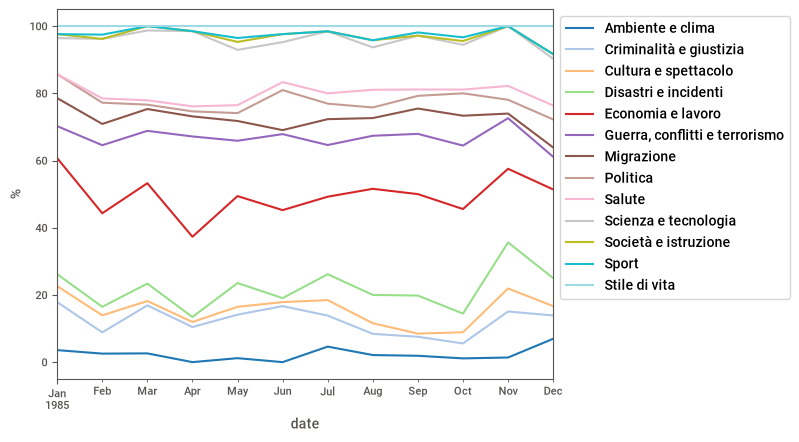

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from nome_progetto.analisi import classify
from nome_progetto.config import IPCT_MEDIA_TOPIC
from nome_progetto.graphs import topic_share

# Classifying each news using a zero-shot vector similarity
# ogni articolo va al topic con la descrizione più simile; labels traduce gli indici nei nomi dei topic
pred, similarity, full_matrix = classify(news_encoded, topic_encoded, labels=IPCT_MEDIA_TOPIC)

# Saving results
df["pred_topic"] = pred
df.to_csv(DATA_DIR/"NYT_sample_processed.csv", index=False)

# Quota di ogni topic nel tempo (per anno, o per mese se c'è un solo anno)
topic_share(df)


# Sentiment analysis 1
Per ogni articolo calcolo il sentiment, quindi se l'articolo ha un tono positivo o negativo. 

C:\Users\napol\Documents\SECOND BRAIN\10_Projects\palestra_python\src\nome_progetto\graphs.py:60: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  date = pd.to_datetime(dates, dayfirst=True)
findfont: Failed to find font weight normal for Roboto, now using 500.


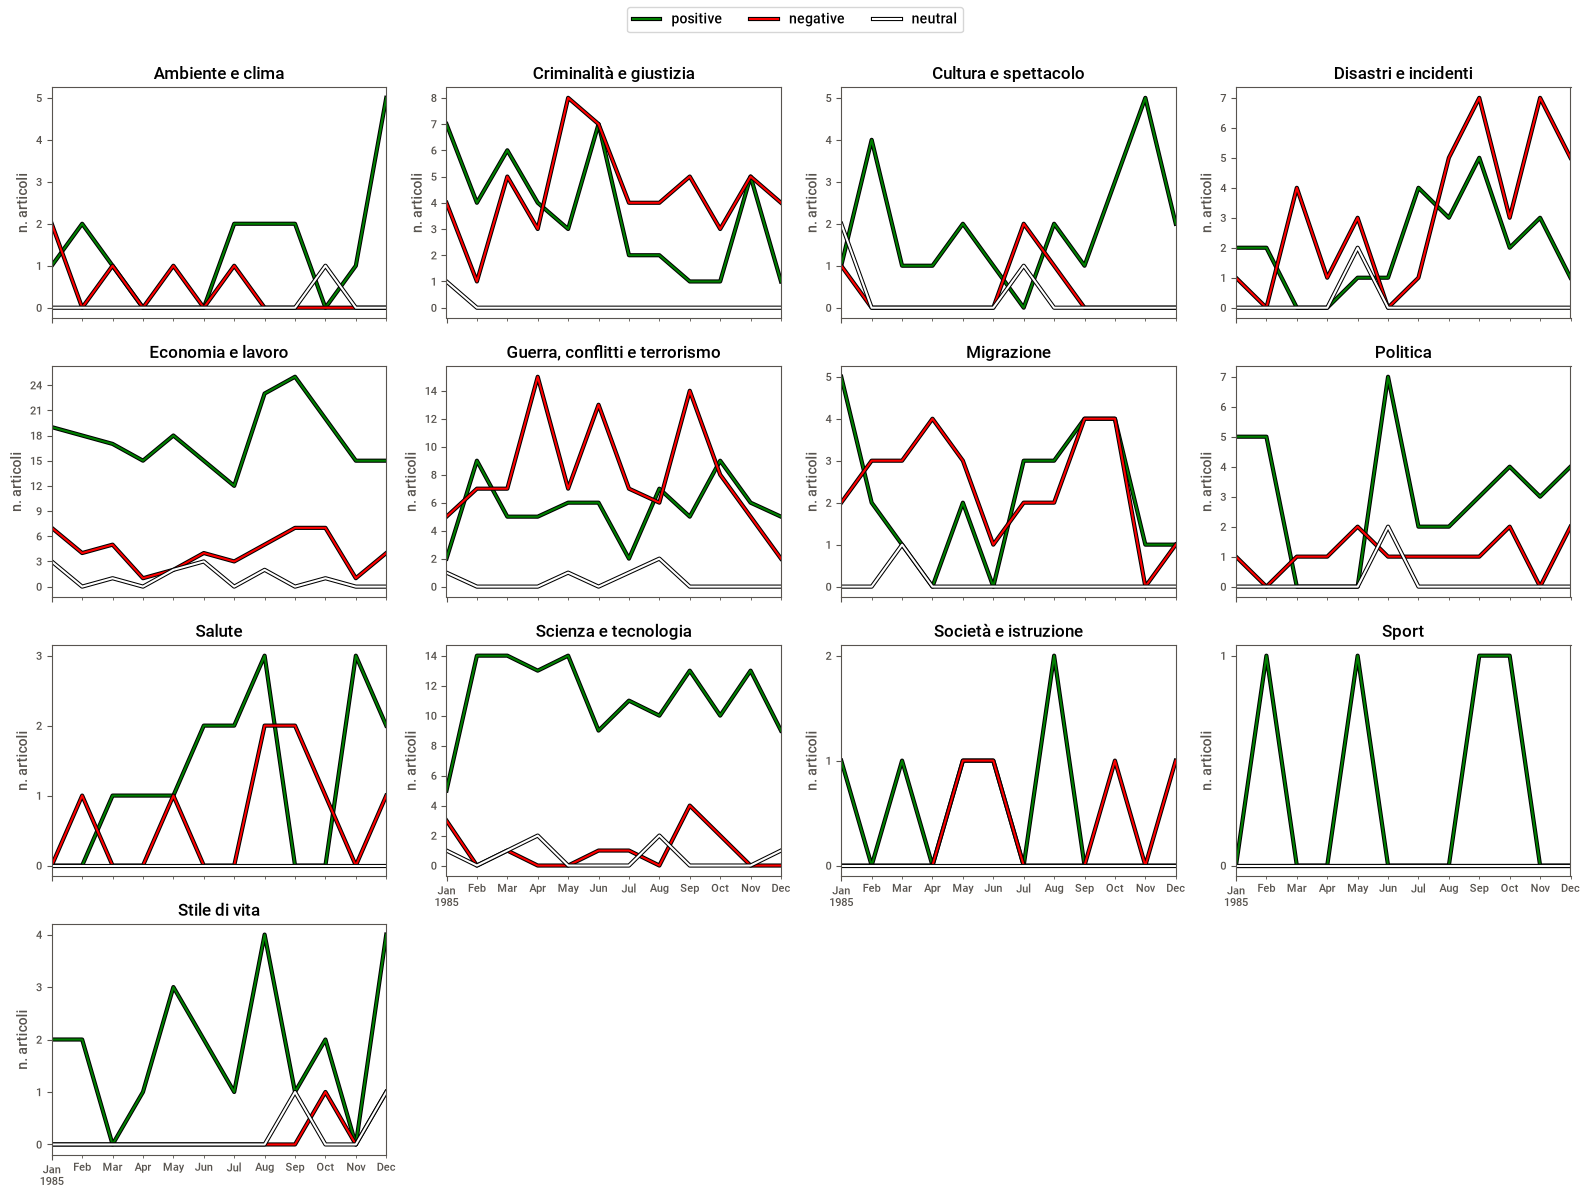

In [14]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from nome_progetto.analisi import label_sentiment
from nome_progetto.graphs import sentiment_by_topic

# Inizializza l'analizzatore
sia = SentimentIntensityAnalyzer()

# polarity_scores restituisce un dict (neg, neu, pos, compound): ogni chiave diventa una colonna
scores = df["full_article"].apply(lambda t: pd.Series(sia.polarity_scores(t)))
# compound va da -1 a 1: lo trasformo in positive / neutral / negative
df["sentiment_label"] = scores["compound"].apply(label_sentiment)

# Numero di articoli positivi / negativi / neutri nel tempo, un grafico per topic
sentiment_by_topic(df, sentiment_col="sentiment_label")

# Sentiment analysis 2

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 17651.91it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
C:\Users\napol\Documents\SECOND BRAIN\10_Projects\palestra_python\src\nome_progetto\graphs.py:60: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  date = pd.to_datetime(dates, dayfirst=True)


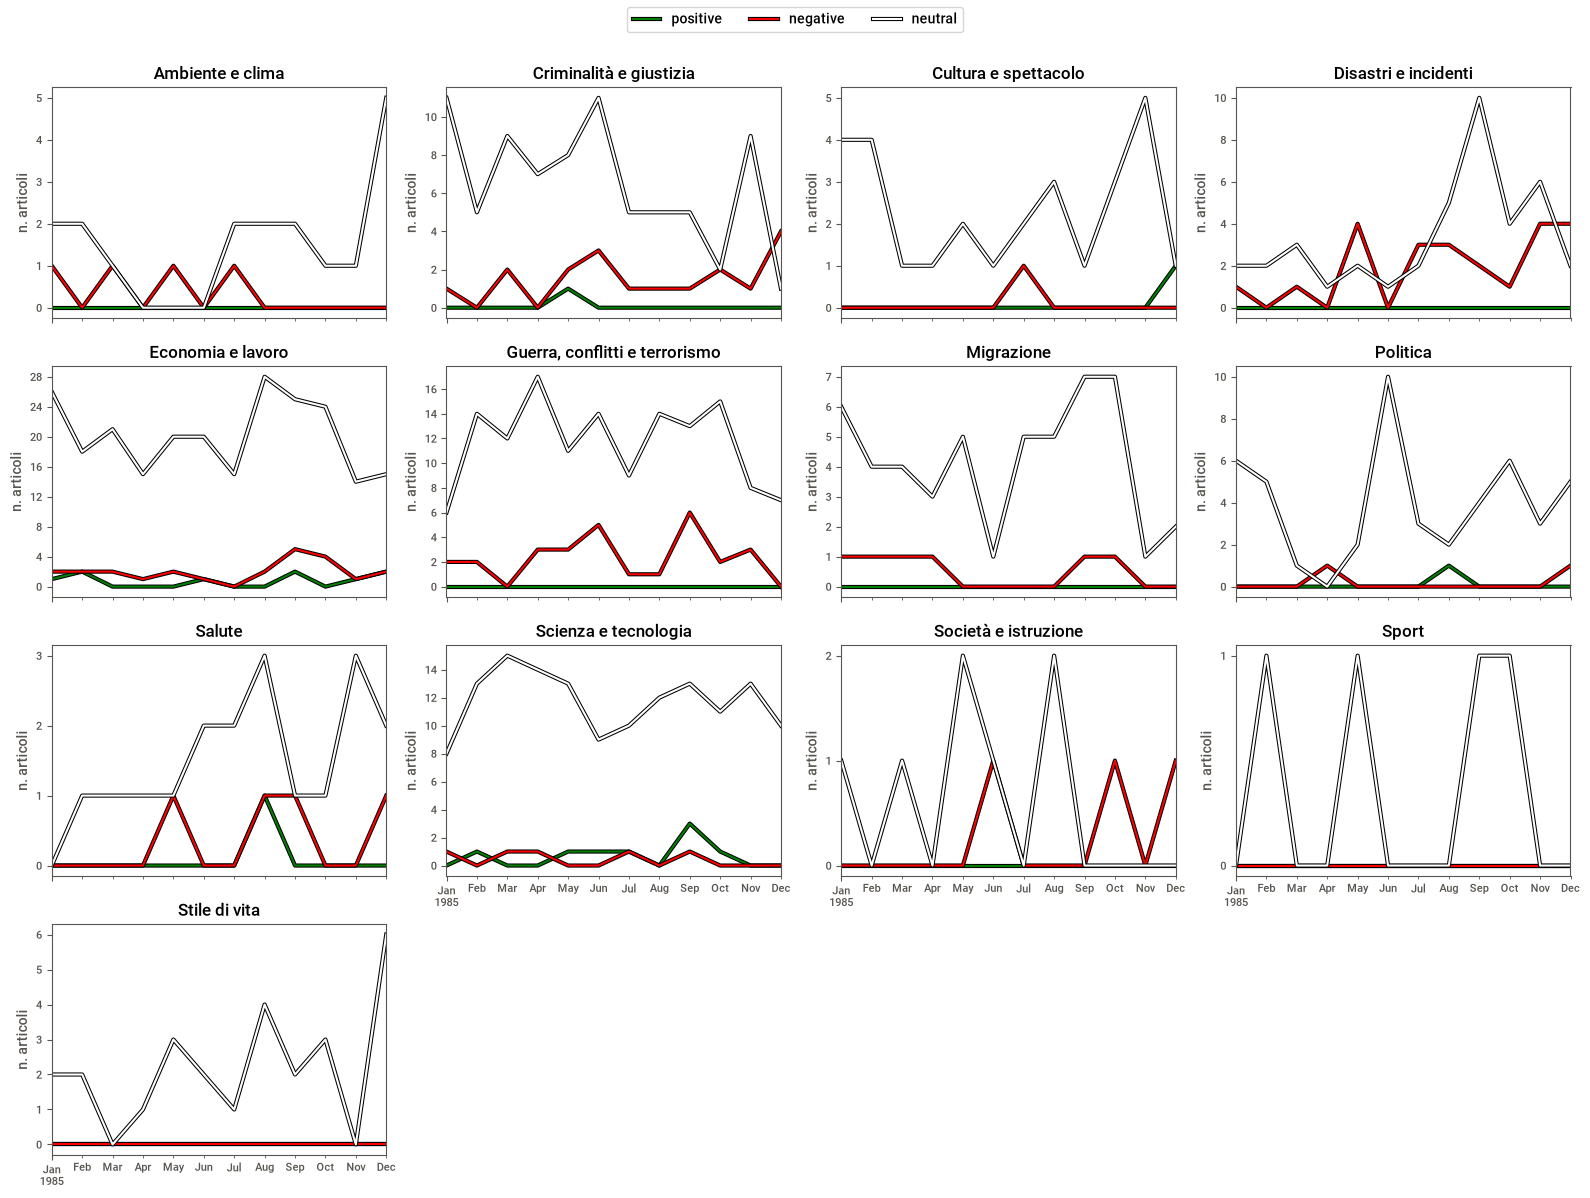

In [15]:
# Problemi: in caso di molti chunk, la memoria si esaurisce.
from nome_progetto.analisi import df_to_token, chunk_prediction, aggrega_chunk
from nome_progetto.graphs import sentiment_by_topic

# testo -> chunk di token -> probabilità per chunk -> media pesata per articolo
df = aggrega_chunk(df, chunk_prediction(df_to_token(df)))

# Stesso grafico della sentiment analysis 1, con le etichette del modello
sentiment_by_topic(df, sentiment_col="sentiment")

In [17]:
# salvo il file con le predizioni dei chunk, per eventuali analisi future
df = df.drop(columns=["negative", "neutral", "positive"], errors="ignore")
df.to_csv(DATA_DIR/"NYT_sample_processed.csv", index=False)